# Step 6: Survey and stock checks

The notebook 3 model explains almost 60% of the differences in overall satisfaction, and notebook 5 showed area deprivation doesn't add anything. So in this notebook I test the other things I could think of that might shape a landlord's score, using data I already have:

| Check | Question | Data |
| --- | --- | --- |
| **A. Sampling error** | Are the differences between landlords real, or could chance in their survey samples produce them? | TSM sample sizes |
| **B. Survey practice** | Does how the survey was run (survey company, who did the interviews, weighting) shift the scores? | TSM survey details |
| **C. Stock profile** | Does the kind of homes a landlord owns (older people's housing, supported housing, building age, houses versus flats, energy ratings) explain anything? | SDR, File 03 |

At the end I put everything from notebooks 5 and 6 into one chart showing **whether each explanation improves the model's predictions**.

## 1. Load the files

In Colab, I upload these **three files at once**:
- the TSM full data set (`2025_TSM_Full_Data_v1.1_FINAL.xlsx`)
- the SDR full data release zip (`PRP_Data_Release_2025_Full_Data_FINAL_V1.1.zip`)
- `landlord_deprivation.csv`, which I made in notebook 5 (it's in the repository's `data` folder)

In [1]:
import pandas as pd
import numpy as np
import zipfile
import re
import statsmodels.formula.api as smf
# scipy.stats has the F and t distributions I need for the tests in check B.
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
import matplotlib.pyplot as plt
import os

# Same upload set-up as notebook 5: find each uploaded file by part of its name.
try:
    from google.colab import files
    uploaded = files.upload()
    def pick(text):
        return next(name for name in uploaded if text in name)
    tsm_path = pick("TSM")
    sdr_path = pick("PRP_Data")
    dep_path = pick("landlord_deprivation")
except ImportError:
    tsm_path = "../data/2025_TSM_Full_Data_v1.1_FINAL.xlsx"
    sdr_path = "../data/PRP_Data_Release_2025_Full_Data_FINAL_V1.1.zip"
    dep_path = "../data/landlord_deprivation.csv"

In [2]:
# The loading code expects the file location in "path".
path = tsm_path

# This is the same loading and joining I worked out in notebooks 1 and 2, just copied in
# so this notebook runs on its own. re is Python's library for matching text patterns.
import re

# RSH puts codes like [X] in cells instead of leaving them blank, so I tell pandas to treat
# them as missing: [X] left blank, [Z] not required, [E] excluded, [U] couldn't be calculated.
missing_codes = ["[X]", "[Z]", "[E]", "[U]"]

# The two sheets have their headers on different rows (row 11 and row 10 in Excel).
lcra = pd.read_excel(path, sheet_name="TSM25_LCRA_Perception", header=10, na_values=missing_codes)
mi = pd.read_excel(path, sheet_name="TSM25_Management_Info", header=9, na_values=missing_codes)

# The survey column names are whole sentences ending in a code like (TP01), so I use a pattern
# to find them and keep just the code as the new name.
tp_pattern = r"^Proportion of respondents who report that they are satisfied.*\((TP\d{2})\)\d*$"
rename_map = {}
for col in lcra.columns:
    match = re.match(tp_pattern, col)
    if match:
        rename_map[col] = match.group(1)

# Shorter names for the other columns I use a lot.
rename_map.update({
    "Landlord name": "landlord",                                          # the landlord's name
    "Landlord code": "code",                                              # RSH's unique ID for each landlord
    "Landlord type": "type",                                              # PRP = housing association, LA = council
    "Landlord group size (homes owned, LCRA and LCHO combined)": "size_band",  # size band
    "Landlord predominant region": "region",                              # region
    "Predominant collection method": "method",                            # main survey method
})

# Pick out the 12 TP codes, then rename and keep only the columns I need.
tp_cols = sorted(name for name in rename_map.values() if name.startswith("TP"))
perception = lcra.rename(columns=rename_map)[
    ["landlord", "code", "type", "size_band", "region", "method"] + tp_cols]


# My function for finding exactly one column whose name contains all the bits of text I give it.
# The assert stops everything if it finds none or several, so I can't grab the wrong column by accident.
def find_col(df, must_contain, starts_with=None):
    """Return the one column whose name contains every text in must_contain."""
    hits = []
    for c in df.columns:
        contains_all = all(text in c for text in must_contain)
        starts_ok = starts_with is None or c.startswith(starts_with)
        if contains_all and starts_ok:
            hits.append(c)
    assert len(hits) == 1, f"Expected 1 match for {must_contain}, found {len(hits)}: {hits}"
    return hits[0]

# The operational measures I want: {my short name: (text in the column name, what it starts with)}.
mi_measures = {
    "gas_safety_pc":            (["(BS01)"], "Proportion"),            # homes with gas safety checks done
    "asb_per_1000":             (["(NM01 1)"], "Number of anti-social"),  # ASB cases per 1,000 homes
    "non_decent_pc":            (["(RP01)"], "Proportion"),            # homes not meeting Decent Homes
    "repairs_on_time_pc":       (["(RP02 1)"], "Proportion"),          # non-emergency repairs on time
    "emergency_on_time_pc":     (["(RP02 2)"], "Proportion"),          # emergency repairs on time
    "repair_target_days":       (["target timescale for non-emergency repairs used to calculate"], "What is your"),
    "complaints_s1_per_1000":   (["(CH01 1)"], "LCRA"),                # stage 1 complaints per 1,000 homes
    "complaints_s1_on_time_pc": (["(CH02 1)"], "LCRA"),                # stage 1 complaints answered on time
    "complaints_s2_per_1000":   (["(CH01 2)"], "LCRA"),                # stage 2 complaints per 1,000 homes
    "complaints_s2_on_time_pc": (["(CH02 2)"], "LCRA"),                # stage 2 complaints answered on time
}
mi_cols = list(mi_measures)

# Build a table of landlord code plus one column per measure, as numbers
# (errors="coerce" turns anything that isn't a number into a blank).
management = pd.DataFrame({"code": mi["Landlord code"]})
for short, (texts, start) in mi_measures.items():
    col = find_col(mi, texts, start)
    management[short] = pd.to_numeric(mi[col], errors="coerce")

# Join the two tables on landlord code (like a VLOOKUP). validate="one_to_one" is a safety check
# that no code appears twice. Then keep housing associations only ("PRP").
df = perception.merge(management, on="code", how="inner", validate="one_to_one")
has = df[df["type"] == "PRP"].copy()
print("Joined landlords:", len(df), " Housing associations:", len(has))

# Same groupings as notebook 3: the rarer survey methods go into "Other", because groups with
# only a handful of landlords give unreliable results.
has["method_group"] = has["method"].where(
    has["method"].isin(["Telephone", "Internet", "Postal"]), "Other")

# Setting a category order means the first one in each list is the "reference group" the model
# compares everything else against. I picked the most common group each time.
has["method_group"] = pd.Categorical(has["method_group"], ["Telephone", "Internet", "Postal", "Other"])
has["size_band"] = pd.Categorical(has["size_band"], ["5,000-40,000", "<5,000", ">40,000"])
has["region"] = pd.Categorical(has["region"], ["South", "North", "Midlands", "London", "Mixed"])

# Codes as text so they match between files (the same fix as notebook 5).
has["code"] = has["code"].astype(str)
# The notebook 3 model's inputs.
operations = ["complaints_s2_per_1000", "non_decent_pc", "repairs_on_time_pc", "complaints_s1_on_time_pc"]
context = "C(method_group) + C(size_band) + C(region)"

Joined landlords: 352  Housing associations: 195


## Check A: Are the differences real, or sampling error?

Every landlord's score comes from a **sample** of tenants, so it has some random error in it, and the smaller the sample, the bigger the error. I came across **funnel plots**, which the NHS uses to compare hospitals fairly. They plot each landlord's score against its sample size, with **control limits** that are wide for small samples and narrow for big ones. A landlord outside the limits is unlikely to be there just by chance.

The limits come from the standard formula for the error in a percentage from a sample of *n* people:

- **standard error** = √( p × (1 − p) ÷ n ), where p is the average satisfaction across all landlords
- **95% limits** = p ± 1.96 standard errors (1 in 20 landlords would fall outside by chance)
- **99.8% limits** = p ± 3.09 standard errors (1 in 500)

To keep it like for like, I only use housing associations that surveyed mainly by **telephone**, the most common method.

In [3]:
# Look up each landlord's sample size by its code (.map works like a VLOOKUP).
sample_sizes = lcra.set_index(lcra["Landlord code"].astype(str))["Total sample size achieved"]
has["n"] = has["code"].map(sample_sizes)

tel = has[has["method"] == "Telephone"].copy()

# The overall average: all the satisfied tenants added up, divided by all the responses (as 0 to 1).
p = (tel["TP01"] / 100 * tel["n"]).sum() / tel["n"].sum()

# Each landlord's standard error, and its z-score: how many standard errors it is from the average.
tel["se"] = np.sqrt(p * (1 - p) / tel["n"])
tel["z"] = (tel["TP01"] / 100 - p) / tel["se"]

# What share of landlords are outside each set of limits? abs() counts both above and below.
outside_95 = (tel["z"].abs() > 1.96).mean() * 100
outside_998 = (tel["z"].abs() > 3.09).mean() * 100

print(f"Pooled average satisfaction: {p * 100:.1f}% across {len(tel)} housing associations")
print(f"Sample sizes range from {tel['n'].min():.0f} to {tel['n'].max():,.0f} responses")
print(f"Outside the 95% limits:   {outside_95:.0f}% of landlords (we'd expect 5% by chance)")
print(f"Outside the 99.8% limits: {outside_998:.0f}% of landlords (we'd expect 0.2% by chance)")

Pooled average satisfaction: 71.9% across 148 housing associations
Sample sizes range from 300 to 7,313 responses
Outside the 95% limits:   82% of landlords (we'd expect 5% by chance)
Outside the 99.8% limits: 74% of landlords (we'd expect 0.2% by chance)


**Most differences between landlords are real.** About three quarters of landlords (74%) are outside the 99.8% limits, when chance alone would put 0.2% there. I looked this up and it's called **overdispersion**: the landlords genuinely differ, by far more than sampling error. That's reassuring for the whole project, because it means I'm explaining real differences rather than noise.

If anything, the limits are a bit too narrow, because survey weighting makes the true error slightly bigger than the simple formula. That doesn't change the conclusion though.

## Check B: Survey practice

The TSM file records, for each landlord:
- which **external survey company** it used, if any
- **who did the interviews**: the survey company, the landlord's own staff, or a mix
- whether responses were **weighted** to match the tenant population

My thinking was: if a survey company tends to produce lower or higher scores (pollsters call these **house effects**), its clients would all come out below or above their predicted scores. So I grouped the notebook 3 model's **residuals** (actual minus predicted) by survey company.

### Clean the survey company names

Landlords typed the company names in themselves, so the same company shows up in lots of forms, like "Acuity Research & Practice Ltd", "Acuity" and "Acuity Research and Practice Limited". I standardised them by looking for a keyword in each name.

In [4]:
# A quick helper to grab the column whose name starts with some text.
def col_starting(text):
    return [col for col in lcra.columns if col.startswith(text)][0]

# The survey details I need, one row per landlord.
survey = pd.DataFrame({
    "code": lcra["Landlord code"].astype(str),                                     # landlord code
    "contractor_raw": lcra["External contractor's name"],                          # company name as typed
    "used_contractor": lcra[col_starting("Have any external contractors")],       # Yes / No
    "interviewer": lcra[col_starting("If interviews were conducted")],            # who did the interviews
    "weighted": lcra[col_starting("Were weighted responses used")],               # Yes / No
})

# Keywords and the standard name each one means. The order matters, because the first match wins.
keywords = [
    ("acuity", "Acuity"), ("iff", "IFF Research"), ("leadership factor", "TLF Research"),
    ("tlf", "TLF Research"), ("arp", "ARP Research"), ("kwest", "Kwest Research"),
    ("m.e.l", "MEL Research"), ("m·e·l", "MEL Research"), ("mel research", "MEL Research"),
    ("cx", "CX Feedback"), ("bmg", "BMG Research"), ("housemark", "Housemark"),
]


# Turn a typed company name into its standard name.
def standard_name(typed):
    """Return the standard survey company name for a name as typed."""
    if pd.isna(typed):
        return None
    # Lower case first, so "ACUITY" and "Acuity" both match "acuity".
    text = str(typed).lower()
    for keyword, name in keywords:
        if keyword in text:
            return name
    # Anything left is one of the many smaller companies.
    return "Other company"


survey["contractor"] = survey["contractor_raw"].apply(standard_name)
survey.loc[survey["used_contractor"] == "No", "contractor"] = "No company (in-house)"

# Join the survey details on and see how many housing associations used each company.
has = has.merge(survey, on="code", how="left", validate="one_to_one")
has["contractor"].value_counts()

contractor
Acuity                   45
IFF Research             32
TLF Research             29
No company (in-house)    24
Other company            23
Kwest Research           12
CX Feedback               8
MEL Research              8
Housemark                 6
ARP Research              6
BMG Research              2
Name: count, dtype: int64

I decided companies with fewer than 5 housing association clients can't really be judged, so they go in with "Other company".

### Residuals by survey company

In [5]:
# Refit the notebook 3 model and save each landlord's residual (actual minus predicted).
model_data = has.dropna(subset=["TP01"] + operations).copy()
baseline = smf.ols(f"TP01 ~ {' + '.join(operations)} + {context}", data=model_data).fit(cov_type="HC3")
model_data["residual"] = baseline.resid

# Put companies with fewer than 5 clients into "Other company".
counts = model_data["contractor"].value_counts()
big_enough = counts[counts >= 5].index
model_data["company"] = model_data["contractor"].where(model_data["contractor"].isin(big_enough), "Other company")


# For one group of landlords: how many, their average residual, and a 95% confidence interval.
# For small groups the t-distribution gives a wider interval than the usual 1.96, which is more honest.
def mean_and_ci(values):
    """Mean, and the 95% confidence interval using the t-distribution."""
    n = len(values)
    mean = values.mean()
    se = values.std() / np.sqrt(n)
    t = stats.t.ppf(0.975, n - 1)
    return pd.Series({"landlords": n, "mean residual": mean, "CI low": mean - t * se, "CI high": mean + t * se})


# Run that for every company and sort by the average.
by_company = model_data.groupby("company")["residual"].apply(mean_and_ci).unstack().sort_values("mean residual")
by_company.round(2)

,landlords,mean residual,CI low,CI high
company,,,,
ARP Research,6.0,-3.25,-7.47,0.97
MEL Research,8.0,-2.63,-5.71,0.44
TLF Research,28.0,-2.50,-5.10,0.10
CX Feedback,8.0,-1.11,-8.13,5.92
Kwest Research,12.0,-1.09,-4.13,1.94
Acuity,45.0,0.40,-1.38,2.18
IFF Research,32.0,0.42,-1.42,2.26
Other company,25.0,1.14,-1.08,3.37
Housemark,6.0,1.40,-6.59,9.39


**Every company's confidence interval crosses zero**, so no survey company clearly produces higher or lower scores than its clients' operations would predict. Landlords that ran their surveys in-house come closest to scoring clearly above prediction (−0.4 to +5.8), so I look at that next.

### Testing survey practice in the model

Next I added survey practice into the notebook 3 model. The survey companies are a **group** of new variables, so to test them all at once I used a **nested F-test**. It asks whether the bigger model fits enough better than the smaller one to be worth the extra variables. A p-value under 0.05 means yes.

The F-test works straight from the residuals: F = (fall in squared error ÷ number of extra variables) ÷ (remaining squared error ÷ remaining degrees of freedom).

In [6]:
# My nested F-test, written out from the formula above.
def nested_f_test(small, big):
    """F statistic and p-value for whether the bigger model fits significantly better."""
    # The total squared error left over in each model.
    rss_small = (small.resid ** 2).sum()
    rss_big = (big.resid ** 2).sum()
    # How many extra variables the bigger model has, and its remaining degrees of freedom.
    extra = big.model.exog.shape[1] - small.model.exog.shape[1]
    df_resid = big.nobs - big.model.exog.shape[1]
    f = ((rss_small - rss_big) / extra) / (rss_big / df_resid)
    # stats.f.sf gives the chance of an F this big if the extra variables did nothing.
    return f, stats.f.sf(f, extra, df_resid)


# Cross-validated R-squared, the same way as notebook 3.
folds = KFold(n_splits=5, shuffle=True, random_state=42)
def cv_r2(result):
    X = pd.DataFrame(result.model.exog, columns=result.model.exog_names).drop(columns="Intercept")
    return cross_val_score(LinearRegression(), X, result.model.endog, cv=folds, scoring="r2").mean()


# The new variables. "Other company" is the reference group for survey company.
model_data["company"] = pd.Categorical(model_data["company"],
                                       ["Other company"] + sorted(set(model_data["company"]) - {"Other company"}))
# 1/0 flags: did the landlord's own staff do the interviews, and were responses weighted?
model_data["staff_interviews"] = (model_data["interviewer"] == "Staff employed directly by the landlord.").astype(int)
model_data["weighted_yes"] = (model_data["weighted"] == "Yes").astype(int)

# The three tests: what each one adds to the model.
tests = {
    "Survey company": "C(company)",
    "Staff did the interviews": "staff_interviews",
    "Weighted responses": "weighted_yes",
}
# Fit each bigger model and compare it with the baseline.
rows = []
for name, extra in tests.items():
    bigger = smf.ols(f"TP01 ~ {' + '.join(operations)} + {context} + {extra}", data=model_data).fit(cov_type="HC3")
    f, p_value = nested_f_test(baseline, bigger)
    rows.append({"test": name, "F-test p-value": p_value, "R-squared": bigger.rsquared,
                 "CV R-squared": cv_r2(bigger)})

print(f"Baseline: R-squared {baseline.rsquared:.3f}, CV R-squared {cv_r2(baseline):.3f}")
pd.DataFrame(rows).set_index("test").round(3)

Baseline: R-squared 0.589, CV R-squared 0.422


,F-test p-value,R-squared,CV R-squared
test,,,
Survey company,0.086,0.623,0.398
Staff did the interviews,0.008,0.605,0.437
Weighted responses,0.965,0.589,0.411


In [7]:
# The staff interview result looked interesting, so I checked how big the effect is.
staff_model = smf.ols(f"TP01 ~ {' + '.join(operations)} + {context} + staff_interviews",
                      data=model_data).fit(cov_type="HC3")
ci = staff_model.conf_int().loc["staff_interviews"]
print(f"Landlord staff interviewing: {staff_model.params['staff_interviews']:+.1f} points "
      f"(95% CI {ci[0]:+.1f} to {ci[1]:+.1f}), across {model_data['staff_interviews'].sum()} landlords")

Landlord staff interviewing: +3.9 points (95% CI +0.3 to +7.4), across 26 landlords


**What I found:**

- **Survey company:** no clear effect overall (F-test p ≈ 0.09), and adding it makes predictions for unseen landlords slightly worse.
- **Weighting:** no effect at all.
- **Who did the interviews: this one is a real finding for the sector.** Landlords whose **own staff** did the interviews score about **4 points higher** than predicted (+3.9, 95% CI +0.3 to +7.4), and the model predicts unseen landlords better with it in. My guess is that tenants are more positive when they're talking to their landlord's staff, which I found is called **social desirability bias**. It's based on 26 landlords, so I'm treating it with some caution. But it's worth knowing when comparing scores across the sector.

## Check C: Stock profile

Could the kind of homes a landlord owns explain differences in satisfaction? SDR **File 03** gives each landlord's stock breakdown, so I built six measures from it, allowing for group structures the same way as notebook 5:

| Measure | Meaning |
| --- | --- |
| `hop_share` | % of low cost rental homes that are housing for older people |
| `supported_share` | % that are supported housing |
| `pre1945_share` | % of homes built before 1945 |
| `post2001_share` | % built since 2001 |
| `house_share` | % that are houses or bungalows (rather than flats) |
| `epc_c_plus` | % of homes with a known energy rating rated C or better |

In [8]:
# My SDR reading function from notebook 5 (notebook 5 explains how it finds the header row).
def read_sdr(zip_path, file_label):
    with zipfile.ZipFile(zip_path) as z:
        name = next(n for n in z.namelist() if file_label in n)
        with z.open(name) as f:
            raw = pd.read_csv(f, encoding="latin-1", header=None)
        header_row = raw.index[raw.iloc[:, 0].astype(str).str.strip() == "PRP name"][0]
        with z.open(name) as f:
            return pd.read_csv(f, encoding="latin-1", header=header_row)


# The group structure lookup from notebook 5: {parent code: [child codes]}.
groups = read_sdr(sdr_path, "File 02")
links = groups[groups["Registered Parent's code"].notna()][
    ["PRP registration number", "Registered Parent's code"]].drop_duplicates()
children = {}
for child, parent in zip(links["PRP registration number"], links["Registered Parent's code"]):
    children.setdefault(str(parent), []).append(str(child))
tsm_codes = set(has["code"])


# A landlord plus its subsidiaries, except any that report TSMs themselves (as in notebook 5).
def group_members(code):
    found, to_check = [code], [code]
    while to_check:
        current = to_check.pop()
        for child in children.get(current, []):
            if child not in found and child not in tsm_codes:
                found.append(child)
                to_check.append(child)
    return found


# The stock profile file: one row per registered company.
profile = read_sdr(sdr_path, "File 03")
profile["code"] = profile["PRP registration number"].astype(str)

In [9]:
# The columns I need, as {my short name: how the column name starts}. The real names are very long.
wanted = {
    "gn_own": "General needs - Low cost rental accommodation owned and directly managed",
    "gn_other": "General needs - Low cost rental accommodation owned by you but managed",
    "sh_own": "Supported housing - Low cost rental accommodation owned and directly",
    "sh_other": "Supported housing - Low cost rental accommodation owned by you but",
    "hop_own": "Housing for older people - Low cost rental accommodation owned and directly",
    "hop_other": "Housing for older people - Low cost rental accommodation owned by you but",
    "pre1919": "Date of Construction - Pre-1919",
    "y1919_44": "Date of Construction - 1919-1944",
    "y2001_10": "Date of Construction - 2001-2010",
    "y2011_20": "Date of Construction - 2011-2020",
    "post2020": "Date of Construction - Post-2020",
    "age_total": "Date of Construction - Total",
    "houses": "Type - House or Bungalow",
    "type_total": "Type - Total",
    "epc_a": "EPC rating - EPC-A", "epc_b": "EPC rating - EPC-B", "epc_c": "EPC rating - EPC-C",
    "epc_d": "EPC rating - EPC-D", "epc_e": "EPC rating - EPC-E", "epc_f": "EPC rating - EPC-F",
    "epc_g": "EPC rating - EPC-G",
}
# Copy each one into a new table under its short name, as numbers.
stock = pd.DataFrame({"code": profile["code"]})
for short, start in wanted.items():
    full_name = next(col for col in profile.columns if col.startswith(start))
    stock[short] = pd.to_numeric(profile[full_name], errors="coerce")
# In the home type counts, "[x]" means the landlord has none of that type, so blank should be 0 here.
for col in ["gn_own", "gn_other", "sh_own", "sh_other", "hop_own", "hop_other"]:
    stock[col] = stock[col].fillna(0)

In [10]:
# For each TSM landlord: add up its whole group's stock, then work out the six percentages.
rows = []
for code in has["code"]:
    # min_count=1 keeps "unknown" as blank rather than turning it into 0.
    s = stock[stock["code"].isin(group_members(code))].drop(columns="code").sum(min_count=1)
    homes = s[["gn_own", "gn_other", "sh_own", "sh_other", "hop_own", "hop_other"]].sum()
    epc_known = s[["epc_a", "epc_b", "epc_c", "epc_d", "epc_e", "epc_f", "epc_g"]].sum()
    # A little helper for percentages that gives a blank instead of an error if the bottom is 0 or missing.
    def pct(top, bottom):
        return top / bottom * 100 if bottom and bottom > 0 else np.nan
    rows.append({
        "code": code,
        "hop_share": pct(s["hop_own"] + s["hop_other"], homes),
        "supported_share": pct(s["sh_own"] + s["sh_other"], homes),
        "pre1945_share": pct(s["pre1919"] + s["y1919_44"], s["age_total"]),
        "post2001_share": pct(s["y2001_10"] + s["y2011_20"] + s["post2020"], s["age_total"]),
        "house_share": pct(s["houses"], s["type_total"]),
        "epc_c_plus": pct(s["epc_a"] + s["epc_b"] + s["epc_c"], epc_known),
    })

stock_profile = pd.DataFrame(rows)
model_data = model_data.merge(stock_profile, on="code", how="left", validate="one_to_one")
stock_cols = ["hop_share", "supported_share", "pre1945_share", "post2001_share", "house_share", "epc_c_plus"]

# The spread of each measure across housing associations.
summary = model_data[stock_cols].describe().T[["count", "25%", "50%", "75%"]]
summary.round(1)

,count,25%,50%,75%
hop_share,194.0,0.6,6.8,12.9
supported_share,194.0,0.2,2.0,5.7
pre1945_share,188.0,10.1,16.4,23.6
post2001_share,185.0,8.1,17.0,26.2
house_share,194.0,48.1,57.8,67.3
epc_c_plus,190.0,71.0,79.7,86.1


Housing associations vary a lot here. The middle half have between 0.6% and 12.9% housing for older people, and between 48% and 67% houses rather than flats. Building age varies too: a typical landlord has about 16% of homes built before 1945 and 17% since 2001.

### Testing stock profile in the model

Building age and energy ratings are missing for a few landlords, so this test uses the 181 housing associations that have every measure. To keep it fair, I refitted the baseline on those same 181 landlords.

In [11]:
# Only landlords with every stock measure, and the baseline model refitted on just them.
stock_data = model_data.dropna(subset=stock_cols).copy()
stock_base = smf.ols(f"TP01 ~ {' + '.join(operations)} + {context}", data=stock_data).fit(cov_type="HC3")

# Test each stock measure on its own, then all six together.
rows = []
for extra in stock_cols + ["all six together"]:
    added = " + ".join(stock_cols) if extra == "all six together" else extra
    bigger = smf.ols(f"TP01 ~ {' + '.join(operations)} + {context} + {added}", data=stock_data).fit(cov_type="HC3")
    f, p_value = nested_f_test(stock_base, bigger)
    rows.append({"added": extra, "F-test p-value": p_value, "R-squared": bigger.rsquared,
                 "CV R-squared": cv_r2(bigger)})

print(f"Baseline on {len(stock_data)} landlords: R-squared {stock_base.rsquared:.3f}, "
      f"CV R-squared {cv_r2(stock_base):.3f}")
pd.DataFrame(rows).set_index("added").round(3)

Baseline on 181 landlords: R-squared 0.606, CV R-squared 0.462


,F-test p-value,R-squared,CV R-squared
added,,,
hop_share,0.995,0.606,0.448
supported_share,0.048,0.615,0.426
pre1945_share,0.159,0.611,0.472
post2001_share,0.202,0.610,0.468
house_share,0.414,0.608,0.456
epc_c_plus,0.261,0.609,0.453
all six together,0.260,0.624,0.387


**What I found:** the type of homes doesn't explain satisfaction once operations are allowed for. Only supported housing passes the F-test (p = 0.048), and that's driven by a handful of landlords that are almost entirely supported housing. Even then it makes predictions for unseen landlords worse (0.462 down to 0.426), so it's not a useful explanation. Adding all six makes predictions for unseen landlords clearly **worse**, which is **overfitting**: the model learns the quirks of these particular landlords instead of general patterns.

## Summary: does each explanation improve the model?

I wanted one comparable number per explanation from notebooks 5 and 6. For each one, I compare the model with that explanation added against the baseline model on **the same landlords**, and record the **change in cross-validated R-squared**: how much better (or worse) the model gets at predicting landlords it hasn't seen.

In [12]:
# Bring in the deprivation scores I made in notebook 5.
deprivation = pd.read_csv(dep_path, dtype={"code": str})
model_data = model_data.merge(deprivation[["code", "dep_IMD", "dep_Barriers"]], on="code", how="left",
                              validate="one_to_one")


# Test one explanation: does adding it improve predictions for unseen landlords?
def test_explanation(extra, needed):
    """F-test and change in cross-validated R-squared when 'extra' is added, on the same landlords."""
    # Only landlords that have everything this test needs, so both models use the same ones.
    data = model_data.dropna(subset=needed).copy()
    small = smf.ols(f"TP01 ~ {' + '.join(operations)} + {context}", data=data).fit(cov_type="HC3")
    big = smf.ols(f"TP01 ~ {' + '.join(operations)} + {context} + {extra}", data=data).fit(cov_type="HC3")
    f, p_value = nested_f_test(small, big)
    return {"landlords": len(data), "F-test p-value": p_value,
            "change in CV R-squared": cv_r2(big) - cv_r2(small)}


# Everything I tested in notebooks 5 and 6: {label: (what to add to the formula, columns it needs)}.
explanations = {
    "Area deprivation (overall IMD)": ("dep_IMD", ["dep_IMD"]),
    "Barriers to housing and services": ("dep_Barriers", ["dep_Barriers"]),
    "Survey company": ("C(company)", ["company"]),
    "Staff did the interviews": ("staff_interviews", ["staff_interviews"]),
    "Weighted responses": ("weighted_yes", ["weighted_yes"]),
    "Stock profile (all six measures)": (" + ".join(stock_cols), stock_cols),
}
tested = pd.DataFrame({label: test_explanation(extra, ["TP01"] + operations + needed)
                       for label, (extra, needed) in explanations.items()}).T
tested = tested.sort_values("change in CV R-squared")
tested.round(3)

,landlords,F-test p-value,change in CV R-squared
Stock profile (all six measures),181.0,0.260,-0.074
Survey company,194.0,0.086,-0.024
Area deprivation (overall IMD),194.0,0.171,-0.014
Weighted responses,194.0,0.965,-0.011
Barriers to housing and services,194.0,0.100,0.001
Staff did the interviews,194.0,0.008,0.015


**Only one explanation improves predictions for unseen landlords: whether the landlord's own staff did the interviews** (cross-validated R² up by 0.015, from 0.422 to 0.437). It's also the only one that passes the F-test (p = 0.008). Barriers to housing and services makes no real difference (+0.001). Everything else makes predictions slightly worse, and the six stock measures together make them clearly worse (−0.074), which is the overfitting I saw earlier.

So the notebook 3 model (four operational measures plus survey method, size and region) is hard to beat with anything else in the public data.

## Charts

Same style as notebooks 4 and 5.

In [13]:
# My house style from notebook 4 (notebook 4 explains each setting).
SURFACE, INK, INK_2, MUTED = "#ffffff", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, HIGHLIGHT, ACCENT, CONTEXT = "#e4e3df", "#c3c2b7", "#2a78d6", "#eb6834", "#c3c2b7"
SOURCE = "Sources: RSH Tenant Satisfaction Measures 2024/25; RSH Statistical Data Return 2025"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Inter", "DejaVu Sans"], "font.size": 10, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2, "axes.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "xtick.major.size": 0, "ytick.major.size": 0, "xtick.minor.size": 0,
    "axes.spines.top": False, "axes.spines.right": False,
})


# This version lets me swap the source line, because the charts here use different data.
def titles(fig, title, subtitle, source=SOURCE):
    fig.text(0.02, 0.98, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.02, 0.925, subtitle, ha="left", va="top", fontsize=10, color=INK_2)
    fig.text(0.02, 0.015, source, ha="left", va="bottom", fontsize=8, color=MUTED)


os.makedirs("charts", exist_ok=True)

### Chart 7: Funnel plot

The limit lines curve in as the sample size grows, which is what gives the funnel its shape. I used a log scale for sample size so the small landlords aren't all squashed on the left. Landlords outside the 99.8% limits are in blue.

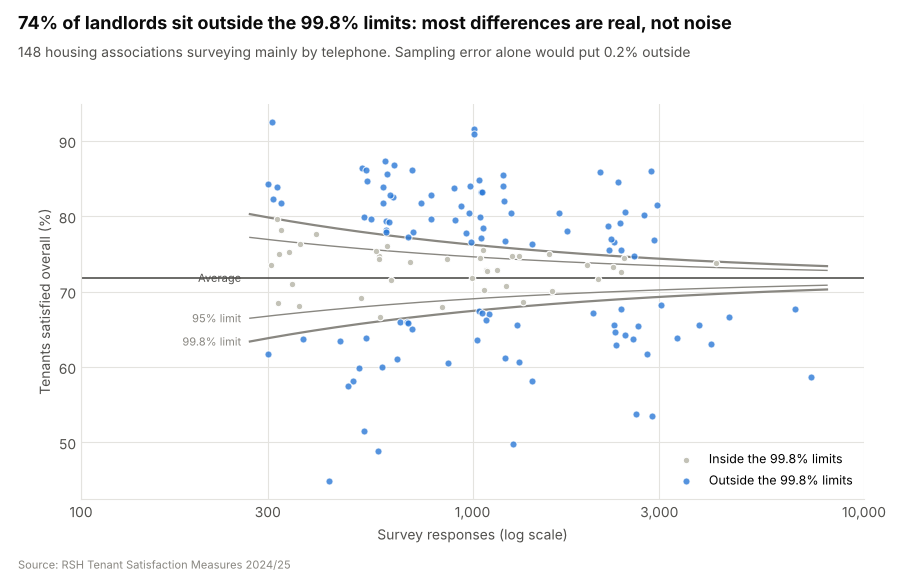

In [14]:
fig, ax = plt.subplots(figsize=(9, 5.8))
fig.subplots_adjust(left=0.09, right=0.96, top=0.82, bottom=0.14)

# 200 sample sizes from smallest to largest, evenly spaced on a log scale, to draw smooth limit lines.
ns = np.logspace(np.log10(tel["n"].min() * 0.9), np.log10(tel["n"].max() * 1.1), 200)
# The 95% (thinner) and 99.8% (thicker) limits, above and below the average.
for z, width, label in [(1.96, 1, "95%"), (3.09, 1.6, "99.8%")]:
    upper = (p + z * np.sqrt(p * (1 - p) / ns)) * 100
    lower = (p - z * np.sqrt(p * (1 - p) / ns)) * 100
    ax.plot(ns, upper, color=MUTED, linewidth=width)
    ax.plot(ns, lower, color=MUTED, linewidth=width)
    # I labelled each line at the left end, where the lines are furthest apart and the labels don't overlap.
    ax.text(ns[0] * 0.95, lower[0], f"{label} limit", ha="right", va="center", fontsize=8, color=MUTED)
ax.axhline(p * 100, color=INK_2, linewidth=1.2)
ax.text(ns[0] * 0.95, p * 100, "Average", ha="right", va="center", fontsize=8, color=INK_2)

# Landlords inside the 99.8% limits in grey, those outside in blue.
outside = tel["z"].abs() > 3.09
ax.scatter(tel.loc[~outside, "n"], tel.loc[~outside, "TP01"], s=22, color=CONTEXT, edgecolors=SURFACE,
           linewidths=0.8, zorder=2, label="Inside the 99.8% limits")
ax.scatter(tel.loc[outside, "n"], tel.loc[outside, "TP01"], s=26, color=HIGHLIGHT, alpha=0.8, edgecolors=SURFACE,
           linewidths=0.8, zorder=3, label="Outside the 99.8% limits")

# Log scale, but with normal numbers on the axis instead of powers of 10.
ax.set_xscale("log")
ax.set_xticks([100, 300, 1000, 3000, 10000], ["100", "300", "1,000", "3,000", "10,000"])
ax.set_xlabel("Survey responses (log scale)")
ax.set_ylabel("Tenants satisfied overall (%)")
ax.legend(loc="lower right", frameon=False, fontsize=9)

titles(fig, f"{outside_998:.0f}% of landlords sit outside the 99.8% limits: most differences are real, not noise",
       f"{len(tel)} housing associations surveying mainly by telephone. Sampling error alone would put 0.2% outside",
       source="Source: RSH Tenant Satisfaction Measures 2024/25")
fig.savefig("charts/7_funnel_plot.png", dpi=200)
plt.show()

### Chart 8: Residuals by survey company

Each company's average residual (actual minus predicted) with its confidence interval. Landlords that ran their surveys in-house are in blue, since they come closest to standing out.

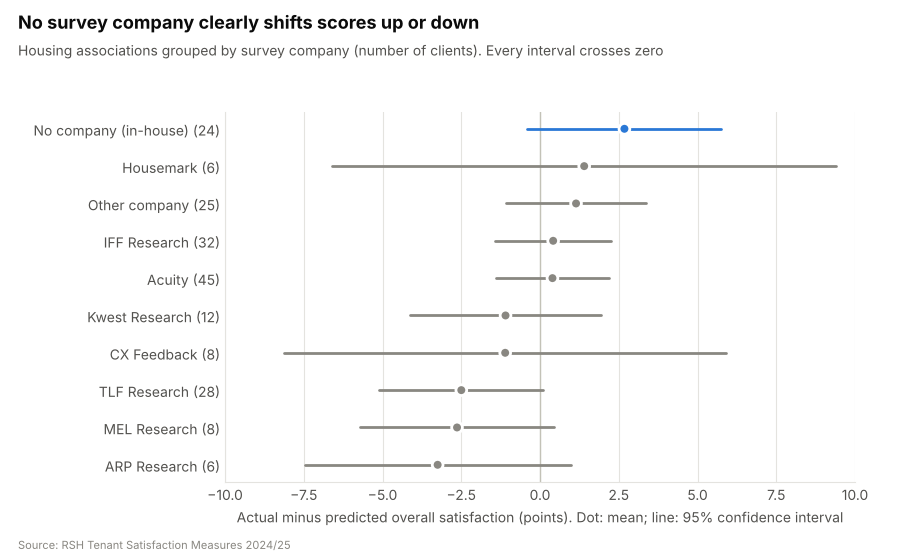

In [15]:
table = by_company.sort_values("mean residual")
y = np.arange(len(table))

fig, ax = plt.subplots(figsize=(9, 5.6))
fig.subplots_adjust(left=0.25, right=0.95, top=0.80, bottom=0.14)

# Zero means "scored exactly as predicted".
ax.axvline(0, color=BASELINE, linewidth=1)
# Whisker and dot for each group: in-house in blue, the survey companies in grey.
colours = [HIGHLIGHT if name == "No company (in-house)" else MUTED for name in table.index]
ax.hlines(y, table["CI low"], table["CI high"], color=colours, linewidth=2, capstyle="round")
ax.scatter(table["mean residual"], y, s=60, color=colours, edgecolors=SURFACE, linewidths=2, zorder=3)

# Labels like "Acuity (45)": the company name and its number of clients.
ax.set_yticks(y, [f"{name} ({int(n)})" for name, n in zip(table.index, table["landlords"])])
ax.set_xlim(-10, 10)
ax.set_xlabel("Actual minus predicted overall satisfaction (points). Dot: mean; line: 95% confidence interval")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)

titles(fig, "No survey company clearly shifts scores up or down",
       "Housing associations grouped by survey company (number of clients). Every interval crosses zero",
       source="Source: RSH Tenant Satisfaction Measures 2024/25")
fig.savefig("charts/8_survey_company.png", dpi=200)
plt.show()

### Chart 9: Everything tested, in one place

This one sums up notebooks 5 and 6 in a single picture: the change in how well the model predicts unseen landlords when each explanation is added.

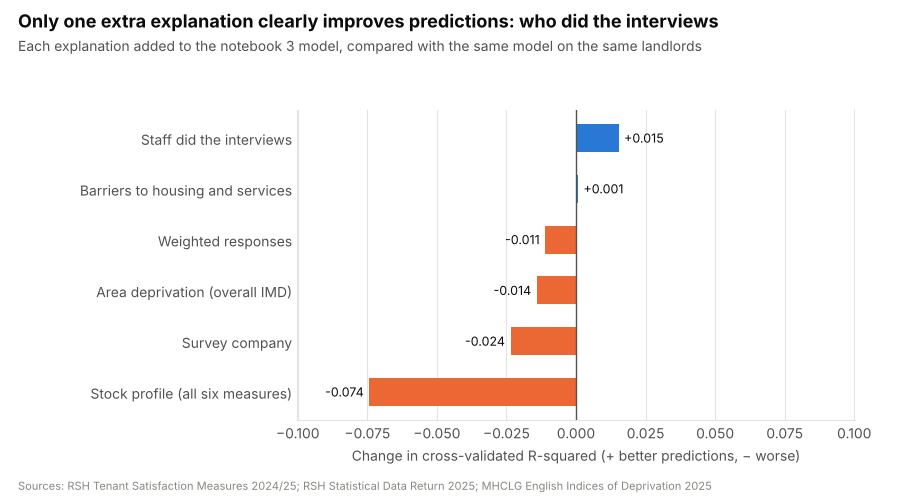

In [16]:
values = tested["change in CV R-squared"].sort_values()
y = np.arange(len(values))

fig, ax = plt.subplots(figsize=(9, 5.0))
fig.subplots_adjust(left=0.33, right=0.95, top=0.78, bottom=0.16)

# Blue bars where an explanation improves predictions, orange where it makes them worse.
colours = [HIGHLIGHT if v > 0 else ACCENT for v in values]
ax.barh(y, values.values, height=0.55, color=colours)
for yi, v in zip(y, values.values):
    # Rounding was showing "-0.000", which looked odd, so tiny values just show as "0.000".
    label = "0.000" if abs(v) < 0.0005 else f"{v:+.3f}"
    ax.text(v + (0.002 if v >= 0 else -0.002), yi, label, ha="left" if v >= 0 else "right",
            va="center", fontsize=9, color=INK)

ax.axvline(0, color=INK_2, linewidth=1)
ax.set_yticks(y, values.index)
lim = max(abs(values.min()), abs(values.max())) * 1.35
ax.set_xlim(-lim, lim)
ax.set_xlabel("Change in cross-validated R-squared (+ better predictions, − worse)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)

titles(fig, "Only one extra explanation clearly improves predictions: who did the interviews",
       "Each explanation added to the notebook 3 model, compared with the same model on the same landlords",
       source=SOURCE + "; MHCLG English Indices of Deprivation 2025")
fig.savefig("charts/9_explanations_tested.png", dpi=200)
plt.show()

## What I found

- **The differences between landlords are real.** 74% of telephone-survey housing associations are outside the 99.8% funnel limits, when sampling error alone would put 0.2% there.
- **Survey company and weighting make no clear difference.** No company's clients sit clearly above or below their predicted scores.
- **Who does the interviews does matter.** Landlords whose own staff did the interviews score about 4 points higher than predicted (+3.9, 95% CI +0.3 to +7.4; 26 landlords), probably because tenants answer more positively to their landlord's staff. That's worth bearing in mind when comparing anyone's TSMs.
- **The type of homes doesn't explain satisfaction** once operations are allowed for, and adding all six stock measures makes predictions worse (overfitting).
- **Across notebooks 5 and 6, nothing in the public data beats the simple notebook 3 model** apart from the staff interviewing flag. Whatever explains the rest of the differences between landlords, such as communication and whether tenants feel listened to, isn't in these datasets.

**Limitations:**
- The survey company and interviewer details are self-reported by landlords, and some groups are small (several companies have under 10 clients; 26 landlords used their own staff).
- The funnel limits use the simple formula for sampling error, which slightly understates the true error for weighted surveys.
- Building age, type and energy ratings are missing for a few landlords, so that test uses 181 landlords rather than 194.

**Next:** notebook 7 adds the previous year's TSMs, to see how things changed.